# **Step 2b – Creación del dataset objetivo: selección y entendimiento de los datos**
**Proyecto TA – Análisis de Datos (1INF03, 2026-2) – Equipo E10**

> *KDD, paso 2:* «Creating a target data set: selecting a data set, or focusing on a subset of variables or data samples, on which discovery is to be performed.»

Se describen los dos bloques de datos, se identifican sus problemas de calidad y se definen la población, la unidad de análisis y las variables que pasarán al Step 3.

Entradas: `datos/0_crudos/ficha_nominal/FichaNominal_consolidado_IDs_v2.txt` (Bloque 1) y `datos/1_consolidados/step2a_nutricion_2026.csv` (Bloque 2).

## Librerías y rutas

In [1]:
import warnings; warnings.filterwarnings("ignore")
import re, json, unicodedata
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import openpyxl
RAW, CONS = Path("../datos/0_crudos"), Path("../datos/1_consolidados")
RES, FIG = Path("../datos/4_resultados"), Path("../figuras")
sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110

## 1. Bloque 1 – Ficha nominal
### 1.1 Lectura y dimensiones
Se leen todas las columnas como texto (`dtype=str`, `keep_default_na=False`) para no perder valores como `NA`, `No tiene` o `No aplica`, que son informativos y se tratan a propósito en el Step 3.

In [2]:
ficha = pd.read_csv(RAW/"ficha_nominal/FichaNominal_consolidado_IDs_v2.txt", sep="|", dtype=str, keep_default_na=False, encoding="utf-8")
print("Filas, columnas:", ficha.shape)
print("Periodos:", ficha["periodo"].nunique(), "| IDs distintos:", ficha["IDs_FichaNominal"].nunique())
ficha.head(3).T

Filas, columnas: (2667, 33)
Periodos: 19 | IDs distintos: 157


,0,1,2
periodo,2025_01,2025_01,2025_01
IDs_FichaNominal,PPA_FN_0001,PPA_FN_0002,PPA_FN_0003
Sexo,F,M,M
Fecha de nacimiento,2022-03-26,2021-11-30,2022-03-28
Departamento,LIMA,LIMA,LIMA
Provincia,LIMA,LIMA,LIMA
Distrito,LIMA,CALLAO,CALLAO
Nacionalidad,PERUANA,PERUANO,PERUANO
Fecha de ingreso,2022-09-06,13/12/2021,2022-04-04
Observaciones y/o comentarios de la forma de ingreso de la NNA,Presunta desprotección familiar,Presunta desprotección familiar,Presunta desprotección familiar


**Interpretación.** Cada fila es un NNA en un mes (formato *panel*: el mismo niño se repite mes a mes). Son 2 667 filas, 33 variables, 19 periodos y 157 IDs. Casi todas las variables son categóricas o fechas: **no hay ninguna variable numérica medida**; la edad y el tiempo en el hogar se derivan de fechas.

### 1.2 Tipos de variable
Se asigna a cada columna su tipo estadístico y se cuenta cuántas categorías distintas tiene.

In [3]:
tipos_var = {
 'periodo':'Temporal (año_mes)','IDs_FichaNominal':'Identificador','Sexo':'Nominal (binaria)','Fecha de nacimiento':'Fecha',
 'Departamento':'Nominal','Provincia':'Nominal','Distrito':'Nominal','Nacionalidad':'Nominal','Fecha de ingreso':'Fecha',
 'Observaciones y/o comentarios de la forma de ingreso de la NNA':'Nominal','Juzgado/UPE':'Nominal','Tipo de documento':'Nominal',
 'Fecha de la Resolucion Administrativa':'Fecha','Situación Legal de la (NNA)':'Nominal','Fecha del Oficio de Ingreso':'Fecha',
 'Nombre de UPE /Juzgado':'Nominal','Comunicado_DGA':'Nominal (binaria)','FECHA ELABORACIÓN Plan de Trabajo individual - PTI':'Fecha',
 'VIGENCIA DEL PTI':'Mixta (fecha/texto)','ESTADO DEL PTI':'Nominal','Instancia que elabora el PTI':'Nominal',
 'Grado de Instrucción':'Ordinal','Último nivel educativo logrado':'Ordinal','Tipo de Institución Educativa':'Nominal',
 'Acceso a capacitación técnico productiva':'Nominal','La NNA actualmente estudia':'Nominal (binaria)',
 'Estado de Salud Física Actual':'Nominal','Presenta Discapacidad (Indicar tipo de discapacidad)':'Nominal / ordinal (severidad)',
 'Nivel Nutricional':'Nominal  <-- OBJETIVO','Soporte Psico-emocional':'Nominal (multi-etiqueta)',
 'Atenciones de salud psicológica':'Nominal (binaria)','Atención en Salud mental especializada':'Nominal','Seguro de Salud (NNA)':'Nominal'}
assert set(tipos_var) == set(ficha.columns), set(ficha.columns) ^ set(tipos_var)
pd.DataFrame({"variable": ficha.columns, "tipo_estadístico": [tipos_var[c] for c in ficha.columns],
              "categorías_distintas": [ficha[c].nunique() for c in ficha.columns]})

,variable,tipo_estadístico,categorías_distintas
0,periodo,Temporal (año_mes),19
1,IDs_FichaNominal,Identificador,157
2,Sexo,Nominal (binaria),2
3,Fecha de nacimiento,Fecha,154
4,Departamento,Nominal,8
5,Provincia,Nominal,12
6,Distrito,Nominal,33
7,Nacionalidad,Nominal,2
8,Fecha de ingreso,Fecha,107
9,Observaciones y/o comentarios de la forma de i...,Nominal,4


### 1.3 Cobertura temporal
Se cuenta cuántos NNA figuran en cada periodo mensual.

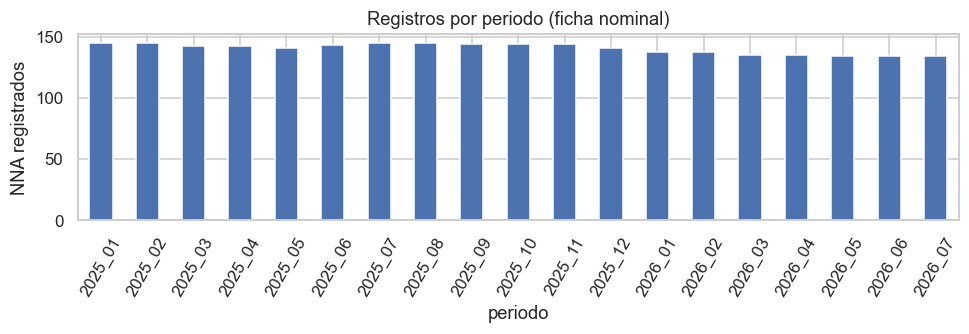

{'count': 19.0, 'mean': 140.4, 'std': 4.3, 'min': 134.0, '25%': 136.0, '50%': 142.0, '75%': 144.0, 'max': 145.0}


In [4]:
filas_mes = ficha.groupby("periodo").size()
ax = filas_mes.plot(kind="bar", figsize=(9,3.2), color="#4C72B0")
ax.set_ylabel("NNA registrados"); ax.set_title("Registros por periodo (ficha nominal)")
plt.xticks(rotation=60); plt.tight_layout(); plt.savefig(FIG/"step2b_registros_por_periodo.png", bbox_inches="tight"); plt.show()
print(filas_mes.describe().round(1).to_dict())

**Interpretación.** La población es estable (entre 134 y 145 NNA por mes, mediana 142). Hay 19 periodos completos, de 2025_01 a 2026_07.

### 1.4 Vacíos reales y valores especiales
Un vacío puede venir disfrazado. Se distingue el **vacío real** (`''`, `NA`) de **`No tiene`** (dato informativo: no existe el plan) y **`No aplica`** (la pregunta no corresponde).

In [5]:
resumen_vacios = pd.DataFrame({"vacío_real(NA)": ficha.isin(["", "NA"]).sum(),
                               "No tiene": ficha.isin(["No tiene", "no tiene"]).sum(),
                               "No aplica": ficha.isin(["No aplica", "No aplicca"]).sum()})
resumen_vacios["% vacío_real"] = (100*resumen_vacios["vacío_real(NA)"]/len(ficha)).round(2)
resumen_vacios = resumen_vacios[resumen_vacios[["vacío_real(NA)","No tiene","No aplica"]].sum(axis=1) > 0]
resumen_vacios.sort_values("vacío_real(NA)", ascending=False)

,vacío_real(NA),No tiene,No aplica,% vacío_real
Distrito,193,0,0,7.24
Fecha de la Resolucion Administrativa,182,0,0,6.82
Fecha del Oficio de Ingreso,58,0,0,2.17
Acceso a capacitación técnico productiva,2,0,2635,0.07
Grado de Instrucción,1,0,0,0.04
FECHA ELABORACIÓN Plan de Trabajo individual - PTI,0,1032,0,0.00
VIGENCIA DEL PTI,0,1033,0,0.00
Instancia que elabora el PTI,0,97,0,0.00
ESTADO DEL PTI,0,1032,0,0.00
Presenta Discapacidad (Indicar tipo de discapacidad),0,2433,0,0.00


Se grafican los tres tipos de valor por variable.

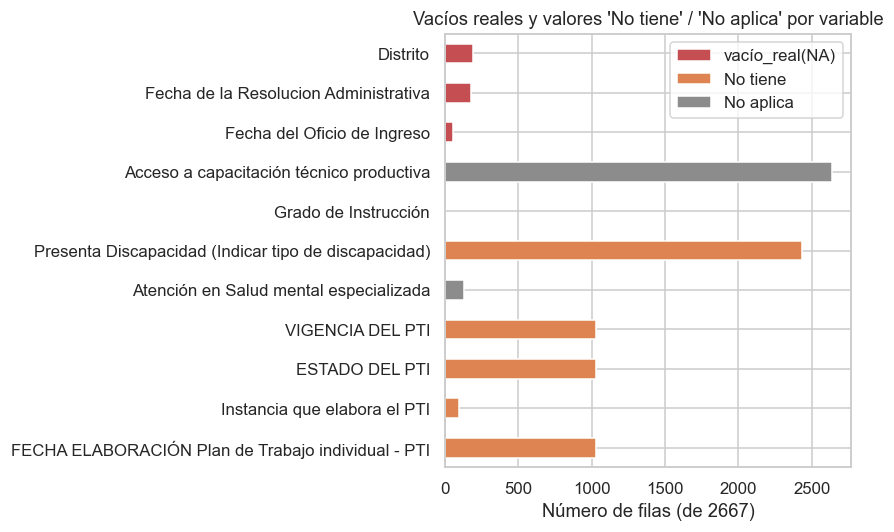

In [6]:
top = resumen_vacios.sort_values("vacío_real(NA)")[["vacío_real(NA)","No tiene","No aplica"]]
top.plot(kind="barh", stacked=True, figsize=(8,5), color=["#C44E52","#DD8452","#8C8C8C"])
plt.xlabel("Número de filas (de %d)" % len(ficha)); plt.title("Vacíos reales y valores 'No tiene' / 'No aplica' por variable")
plt.tight_layout(); plt.savefig(FIG/"step2b_vacios.png", bbox_inches="tight"); plt.show()

**Interpretación.**
- Los **vacíos reales son pocos**: `Distrito` (193 filas, 7,2 %), `Fecha de la Resolución Administrativa` (182) y `Fecha del Oficio de Ingreso` (58). Ninguna variable supera el 8 %.
- `No tiene` en el PTI (≈1 030 filas) **no es un dato perdido**: el niño aún no tiene Plan de Trabajo Individual. En discapacidad, `No tiene` (2 433) es la ausencia de discapacidad. Se conservan como categorías.
- `No aplica` en capacitación técnica (2 635 de 2 667 filas) hace casi constante a esa variable.

### 1.5 Formatos de fecha
Se cuenta cuántos valores de cada columna de fecha siguen cada formato.

In [7]:
cols_fecha = ['Fecha de nacimiento','Fecha de ingreso','Fecha de la Resolucion Administrativa',
              'Fecha del Oficio de Ingreso','FECHA ELABORACIÓN Plan de Trabajo individual - PTI']
pd.DataFrame([{"variable": c,
               "AAAA-MM-DD": ficha[c].str.fullmatch(r"\d{4}-\d{2}-\d{2}").sum(),
               "DD/MM/AAAA": ficha[c].str.fullmatch(r"\d{2}/\d{2}/\d{4}").sum(),
               "DD/MM/AA": ficha[c].str.fullmatch(r"\d{2}/\d{2}/\d{2}").sum(),
               "sin fecha (NA / No tiene / vacío)": ficha[c].isin(["NA","No tiene",""]).sum()} for c in cols_fecha]).set_index("variable")

,AAAA-MM-DD,DD/MM/AAAA,DD/MM/AA,sin fecha (NA / No tiene / vacío)
variable,,,,
Fecha de nacimiento,2560,107,0,0
Fecha de ingreso,1739,928,0,0
Fecha de la Resolucion Administrativa,2002,464,19,182
Fecha del Oficio de Ingreso,2183,426,0,58
FECHA ELABORACIÓN Plan de Trabajo individual - PTI,1635,0,0,1032


**Interpretación.** Cuatro de las cinco fechas mezclan `AAAA-MM-DD` con `DD/MM/AAAA` (p. ej. 928 fechas de ingreso en el segundo formato), y la fecha de resolución trae además 19 valores con año corto (`DD/MM/AA`). Un `pd.to_datetime` sin formato interpretaría mal `dd/mm` como `mm/dd` o dejaría vacíos; por eso se convierten **formato por formato**.

### 1.6 Identificadores: ¿un ID = un niño?
Se verifica si `IDs_FichaNominal` identifica a un solo niño comparando sexo y fecha de nacimiento dentro de cada ID.

In [8]:
ninos_por_id = ficha.drop_duplicates(["IDs_FichaNominal","Sexo","Fecha de nacimiento"]).groupby("IDs_FichaNominal").size()
colisiones = ninos_por_id[ninos_por_id > 1]
print("IDs que agrupan más de un niño distinto:\n", colisiones.to_string())
print("\nFilas por ID:", ficha.groupby("IDs_FichaNominal").size().describe().round(1).to_dict())
ficha[ficha["IDs_FichaNominal"]=="PPA_FN_0020"].drop_duplicates(["Sexo","Fecha de nacimiento"])[["periodo","IDs_FichaNominal","Sexo","Fecha de nacimiento","Fecha de ingreso"]]

IDs que agrupan más de un niño distinto:
 IDs_FichaNominal
PPA_FN_0010    2
PPA_FN_0020    5
PPA_FN_0025    2
PPA_FN_0127    2

Filas por ID: {'count': 157.0, 'mean': 17.0, 'std': 5.2, 'min': 1.0, '25%': 19.0, '50%': 19.0, '75%': 19.0, 'max': 36.0}


,periodo,IDs_FichaNominal,Sexo,Fecha de nacimiento,Fecha de ingreso
19,2025_01,PPA_FN_0020,M,2017-04-24,19/05/2021
23,2025_01,PPA_FN_0020,F,2017-12-14,2018-01-08
144,2025_01,PPA_FN_0020,F,2024-12-28,2024-12-30
285,2025_02,PPA_FN_0020,M,2025-01-12,2025-06-17
289,2025_02,PPA_FN_0020,M,2025-06-01,2025-07-15


**Interpretación.** **El ID no es único por niño**: 4 IDs (`PPA_FN_0010`, `0020`, `0025`, `0127`) se reutilizan para niños con distinto sexo o fecha de nacimiento; `PPA_FN_0020` agrupa a 5 niños. Por eso un ID llega a 36 filas cuando lo esperable es como máximo 19. Si no se corrige, se mezclarían historias de niños distintos. **Decisión (Step 3):** clave de niño = ID + sexo + fecha de nacimiento.

### 1.7 Variables numéricas derivadas: edad y tiempo en el hogar
La ficha no trae variables numéricas medidas. Se calculan **edad** (años) y **tiempo en el hogar** (meses) con fecha de referencia = fin del mes del registro. Es un cálculo preliminar; la versión definitiva, con sus reglas, está en el Step 3.

In [9]:
def parse_fecha(s):
    """Convierte formato por formato (sin dejar que pandas adivine día/mes)."""
    s = s.str.strip()
    f = pd.to_datetime(s, format="%Y-%m-%d", errors="coerce")
    for fmt in ["%d/%m/%Y", "%d/%m/%y"]:
        m = f.isna(); f[m] = pd.to_datetime(s[m], format=fmt, errors="coerce")
    return f
t = ficha[["periodo","IDs_FichaNominal","Sexo"]].copy()
t["nac"] = parse_fecha(ficha["Fecha de nacimiento"]); t["ing"] = parse_fecha(ficha["Fecha de ingreso"])
t["ref"] = pd.to_datetime(t["periodo"].str.replace("_","-")+"-01") + pd.offsets.MonthEnd(0)
t["edad_años"] = (t["ref"]-t["nac"]).dt.days/365.25
t["tiempo_hogar_meses"] = (t["ref"]-t["ing"]).dt.days/30.44
num = t[["edad_años","tiempo_hogar_meses"]]
desc = num.describe().T
desc["CV(%)"] = (100*num.std()/num.mean()).round(1); desc["asimetría"] = num.skew().round(2); desc["curtosis"] = num.kurt().round(2)
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,CV(%),asimetría,curtosis
edad_años,2667.0,10.32,4.79,-0.25,6.67,10.52,13.89,28.71,46.4,0.16,0.06
tiempo_hogar_meses,2667.0,69.20,53.14,-4.50,25.41,58.77,101.35,331.87,76.8,1.20,2.46


Se grafican sus distribuciones (con media y mediana) y se cuentan las fechas imposibles.

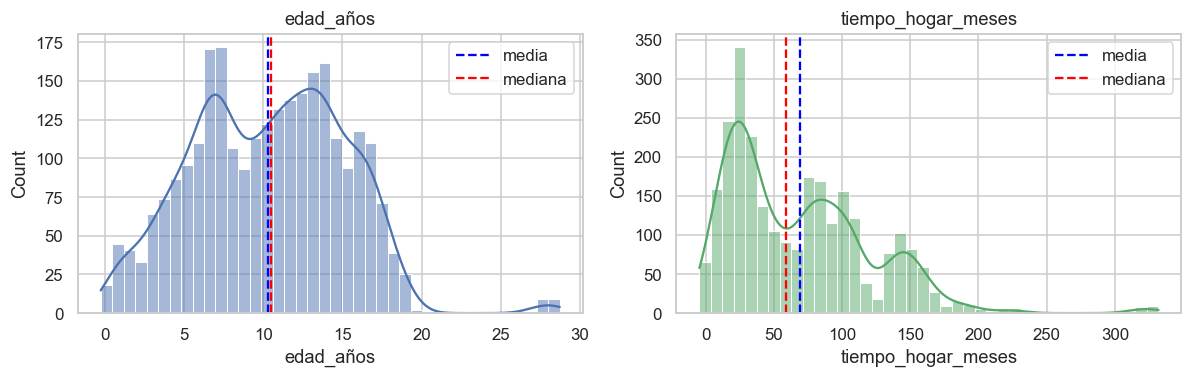

Ingreso anterior al nacimiento: 76 | ingreso posterior al registro: 13 | edad negativa: 2


In [10]:
fig, axs = plt.subplots(1, 2, figsize=(11,3.6))
for ax, c, col in zip(axs, num.columns, ["#4C72B0","#55A868"]):
    sns.histplot(num[c].dropna(), bins=40, kde=True, ax=ax, color=col)
    ax.axvline(num[c].mean(), color="blue", ls="--", label="media"); ax.axvline(num[c].median(), color="red", ls="--", label="mediana")
    ax.set_title(c); ax.legend()
plt.tight_layout(); plt.savefig(FIG/"step2b_hist_edad_tiempo.png", bbox_inches="tight"); plt.show()
n_ing_ant = int((t["ing"] < t["nac"]).sum()); n_ing_post = int((t["ing"] > t["ref"]).sum()); n_edad_neg = int((t["edad_años"] < 0).sum())
print("Ingreso anterior al nacimiento:", n_ing_ant, "| ingreso posterior al registro:", n_ing_post, "| edad negativa:", n_edad_neg)

**Interpretación.**
- **Edad:** media ≈ mediana (10,3 y 10,5 años), distribución amplia y casi simétrica (asimetría 0,16). Hay registros de mayores de edad (hasta 28,7 años), lo que se tendrá en cuenta al delimitar la población.
- **Tiempo en el hogar:** asimetría positiva (1,20; media 69 > mediana 59 meses): la mayoría lleva pocos años y unos pocos más de 20. No son errores, sino casos reales de larga estancia.
- **Fechas imposibles:** 76 filas con ingreso **anterior al nacimiento**, 13 con ingreso **posterior al registro** y 2 con **edad negativa** (nacimiento posterior al mes del registro). Son errores de digitación que se tratan en el Step 3.

### 1.8 Variable objetivo (`Nivel Nutricional`) tal como llega
Se revisan las variantes de texto de la etiqueta.

Variantes distintas de texto: 29


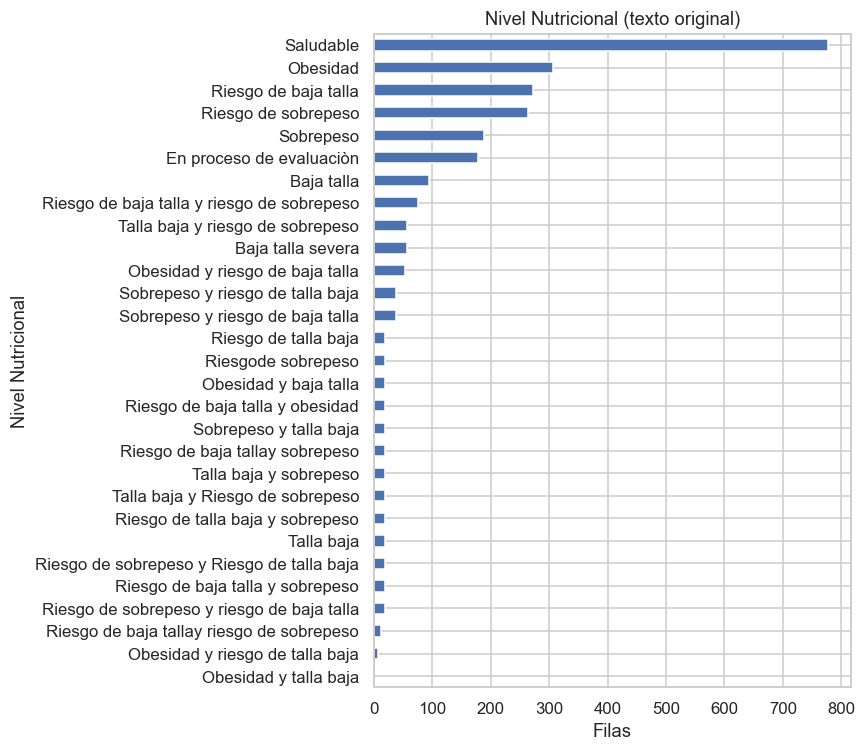

In [11]:
nutri_raw = ficha["Nivel Nutricional"].str.replace(r"\s+", " ", regex=True).str.strip()
print("Variantes distintas de texto:", nutri_raw.nunique())
nutri_raw.value_counts().sort_values().plot(kind="barh", figsize=(8,7), color="#4C72B0"); plt.title("Nivel Nutricional (texto original)")
plt.xlabel("Filas"); plt.tight_layout(); plt.savefig(FIG/"step2b_nivel_nutricional_raw.png", bbox_inches="tight"); plt.show()

**Interpretación.** La etiqueta **no es una variable limpia**: 29 variantes de texto que mezclan estados simples (`Saludable`, `Obesidad`, `Sobrepeso`, `Baja talla`, `Riesgo…`) con **combinaciones** (`Sobrepeso y riesgo de talla baja`) y errores de escritura (`Riesgode sobrepeso`, `Riesgo de baja tallay sobrepeso`). Además existe `En proceso de evaluación`, que **no es un diagnóstico**. Hay que construir una etiqueta consistente (Step 3).

### 1.9 Variables categóricas con variantes de escritura
Se listan los valores de las principales categóricas para detectar variables constantes y variantes de una misma categoría.

In [12]:
for c in ['Sexo','Nacionalidad','Situación Legal de la (NNA)','Nombre de UPE /Juzgado','ESTADO DEL PTI','La NNA actualmente estudia',
          'Tipo de Institución Educativa','Estado de Salud Física Actual','Presenta Discapacidad (Indicar tipo de discapacidad)',
          'Atención en Salud mental especializada','Seguro de Salud (NNA)','Comunicado_DGA','Acceso a capacitación técnico productiva']:
    print("###", c, "->", ficha[c].str.strip().value_counts().to_dict(), "\n")
print("Soporte Psico-emocional: variantes distintas =", ficha['Soporte Psico-emocional'].str.strip().nunique())

### Sexo -> {'M': 1507, 'F': 1160} 

### Nacionalidad -> {'PERUANA': 1601, 'PERUANO': 1066} 

### Situación Legal de la (NNA) -> {'Desprotección Familiar Provisional': 2186, 'Desprotección Familiar Definitiva': 235, 'Acogimiento residencial en calidad de urgente': 192, 'Desprotección Familiar': 24, 'DECIMO PRIMER JUZGADO DE FAMILIA DE LIMA': 19, 'Auto de abandono': 11} 

### Nombre de UPE /Juzgado -> {'UPE LIMA NORTE CALLAO': 896, 'UPE LIMA ESTE': 772, 'UPE LIMA': 741, 'UPE LIMA SUR': 107, 'UPE-LIMA-SUR': 80, '11 JFL': 19, 'UIT LIMA': 19, 'UPE LIMA CENTRO': 19, 'DGA': 14} 

### ESTADO DEL PTI -> {'Actual': 1059, 'No tiene': 999, 'Vencido': 576, 'no tiene': 33} 

### La NNA actualmente estudia -> {'Si': 2313, 'No': 207, 'si': 129, 'NO': 18} 

### Tipo de Institución Educativa -> {'Educación Básica Regular -EBR': 2320, 'Ninguno': 198, 'Cebe': 70, 'Tècnico': 25, 'Taller don Bosco': 20, 'Ceba': 15, 'educación Básica Alternativa -EBR': 14, 'Técnico': 5} 

### Estado de Salud Física Actual -

**Interpretación.**
- `Comunicado_DGA` vale `TRUE` en el 100 % de las filas: **constante, sin información**.
- `Nacionalidad` solo alterna entre `PERUANA` y `PERUANO`, es decir, el género gramatical: **sin información**.
- `Seguro de Salud` es `SIS` en 2 664 de 2 667 filas y `Acceso a capacitación…` es `No aplica` en el 99 %: **casi constantes**.
- Hay variantes de escritura de una misma categoría: `Si/si` y `No/NO` en *estudia*, `UPE LIMA SUR` y `UPE-LIMA-SUR`, `Tècnico/Técnico`, `ANEMIA/Anemia`, `No tiene/no tiene` en el PTI y 53 variantes de `Soporte Psico-emocional`. Se normalizan en el Step 3.

## 2. Bloque 2 – Nutrición 2026 (mediciones)
### 2.1 Lectura y cobertura
Se lee el consolidado del Step 2a y se cuenta cuántas evaluaciones hay por hogar y mes.

In [13]:
nutri = pd.read_csv(CONS/"step2a_nutricion_2026.csv", sep="|")
print("Filas, columnas:", nutri.shape)
cobertura = pd.crosstab(nutri["casa"], nutri["periodo"])
cobertura["Total"] = cobertura.sum(axis=1); cobertura.loc["Total"] = cobertura.sum()
cobertura

Filas, columnas: (379, 20)


periodo,2026_01,2026_02,2026_03,2026_04,2026_06,2026_08,Total
casa,,,,,,,
INFANTES,33,7,6,30,30,0,106
MATOGROSO HOMBRES,32,0,0,20,18,17,87
MATOGROSO MUJERES,28,0,0,15,15,15,73
MIGUEL ECHENIQUE,17,0,0,16,17,0,50
TOMAS VALLE,22,0,0,20,21,0,63
Total,132,7,6,101,101,32,379


**Interpretación.** El Bloque 2 cubre **seis meses de 2026** (enero, febrero, marzo, abril, junio y agosto) y **no todos los hogares todos los meses**: febrero y marzo solo traen Infantes y agosto solo los hogares Matogroso. **Faltan mayo y julio.** Coincide con la frecuencia descrita por la institución (infantes cada 1–2 meses, adolescentes cada ≈3 meses) y reduce la muestra utilizable.

### 2.2 Vacíos y descripción de las medidas
Se calcula el % de vacíos por columna y la descripción de peso, talla e IMC.

In [14]:
print("Vacíos (%):"); print((100*nutri.isna().mean()).round(1).sort_values(ascending=False).to_string())
med = nutri[["Peso_kg","Talla_cm","IMC_valor"]]
d2 = med.describe().T
d2["CV(%)"] = (100*med.std()/med.mean()).round(1); d2["asimetría"] = med.skew().round(2); d2.round(2)

Vacíos (%):
Perimetro_cefalico    98.4
Presion_arterial      95.0
P/T_OMS               86.0
P/E_INS               83.9
P/T_INS               82.8
P/E_OMS               64.1
IMC_INS               16.1
IMC_OMS                4.7
T/E_OMS                0.5
T/E_INS                0.5
archivo                0.0
periodo                0.0
casa                   0.0
hoja                   0.0
IMC_valor              0.0
imc_recalculado        0.0
nac                    0.0
IDs_FichaNominal       0.0
Peso_kg                0.0
Talla_cm               0.0


,count,mean,std,min,25%,50%,75%,max,CV(%),asimetría
Peso_kg,379.0,36.11,18.69,7.65,21.33,31.25,49.95,95.45,51.8,0.72
Talla_cm,379.0,129.52,25.02,70.30,113.55,132.00,151.00,176.80,19.3,-0.37
IMC_valor,379.0,19.89,4.13,13.61,16.88,18.93,22.01,40.29,20.8,1.63


Se listan las variantes de texto de los diagnósticos OMS de talla e IMC, para ver los errores de escritura.

In [15]:
for c in ["T/E_OMS", "IMC_OMS", "P/E_OMS"]:
    print(c, "->", nutri[c].value_counts().to_dict(), "\n")

T/E_OMS -> {'NORMAL': 167, 'RIESGO TALLA BAJA': 79, 'TALLA BAJA': 55, 'TALLA BAJA SEVERA': 27, 'Normal': 24, 'ALTO': 12, 'Riesgo de talla baja': 5, 'Talla baja': 3, 'ALTA': 2, 'RIESGO TALA BAJA': 2, 'RIESO TALLA BAJA': 1} 

IMC_OMS -> {'NORMAL': 155, 'RIESGO SOBREPESO': 74, 'SOBREPESO': 54, 'OBESIDAD': 25, 'Normal': 20, 'RIESGO BAJO PESO': 11, 'Sobrepeso': 4, 'Riesgo de Sobrepeso': 4, 'RIESGO DE SOBREPESO': 4, 'BAJO PESO': 3, 'RIESGO SOBRE PESO': 3, 'Riesgo de sobrepeso': 3, 'Riego de delgadez o riesgo de bajo peso': 1} 

P/E_OMS -> {'NORMAL': 85, 'RIESGO SOBREPESO': 19, 'SOBREPESO': 13, 'RIESGO BAJO PESO': 9, 'OBESIDAD': 5, 'BAJO PESO': 4, 'BAJO PESO SEVERO': 1} 



**Interpretación.**
- Peso, talla e IMC están **completos** (el IMC de marzo se recalculó en el Step 2a). `Perímetro cefálico` (98 % vacío) y `Presión arterial` (95 %) están **casi vacíos** y se descartan.
- Los vacíos de los diagnósticos son **estructurales**: P/E y P/T solo se usan en menores de 5 años; T/E se registra casi siempre (0,5 % vacío).
- Los diagnósticos tienen variantes de escritura (`RIESGO TALA BAJA`, `RIESO TALLA BAJA`, `ALTA/ALTO`, mayúsculas y minúsculas) que se normalizan en el Step 3.
- El rango de peso (7,7 a 95,5 kg) y de talla refleja la mezcla de edades: la dispersión es esperable, no necesariamente un atípico.

### 2.3 Cruce con la ficha
Se verifica que los IDs y las fechas de nacimiento del Bloque 2 existan en la ficha (es lo que permitirá unir medición y etiqueta).

In [16]:
ficha_k = ficha.assign(nac=parse_fecha(ficha["Fecha de nacimiento"]).dt.strftime("%Y-%m-%d"))[["IDs_FichaNominal","nac"]].drop_duplicates()
print("IDs del Bloque 2:", nutri["IDs_FichaNominal"].nunique(),
      "| % de filas cuyo ID existe en la ficha:", round(100*nutri["IDs_FichaNominal"].isin(ficha["IDs_FichaNominal"]).mean(), 1))
par = nutri.merge(ficha_k, on=["IDs_FichaNominal","nac"], how="left", indicator=True)
print("% de filas cuyo par (ID, fecha de nacimiento) existe en la ficha:", round(100*(par["_merge"]=="both").mean(), 1))
print("Periodos del Bloque 2 presentes en la ficha:", sorted(set(nutri["periodo"]) & set(ficha["periodo"])),
      "| ausentes:", sorted(set(nutri["periodo"]) - set(ficha["periodo"])))

IDs del Bloque 2: 140 | % de filas cuyo ID existe en la ficha: 100.0
% de filas cuyo par (ID, fecha de nacimiento) existe en la ficha: 97.1
Periodos del Bloque 2 presentes en la ficha: ['2026_01', '2026_02', '2026_03', '2026_04', '2026_06'] | ausentes: ['2026_08']


**Interpretación.**
- **Todos los IDs** del Bloque 2 existen en la ficha. Agosto (32 evaluaciones) **no tiene ficha** del mismo mes, porque la ficha termina en 2026_07: esas evaluaciones solo sirven para describir, no para cruzar con la etiqueta.
- El 2,9 % de las filas (11, de 4 niños) **no encuentra su par (ID, fecha de nacimiento)** en la ficha porque las fechas difieren: en `PPA_FN_0004` y `PPA_FN_0066` día y mes están **invertidos** (p. ej. 2023-01-09 frente a 2023-09-01) y en `PPA_FN_0028` y `PPA_FN_0064` difieren en 1 y 4 días. La edad escrita por la nutricionista confirma la fecha del Bloque 2 (p. ej. `PPA_FN_0004`: "3 años 1 mes" en enero de 2026).
- **Decisión de ejecución (Step 3):** el cruce se hace por **periodo + ID**; la fecha de nacimiento solo se usa para distinguir a los niños de los 4 IDs reutilizados. La edad de la evaluación se calcula con la fecha del Bloque 2.

### 2.4 ¿Las mediciones se hicieron en el mes del archivo?
La fecha de evaluación no está registrada; se asumirá el día 15 del mes del archivo. Para comprobarlo se compara la **edad escrita a mano** por la nutricionista con la edad calculada al día 15 de ese mes. Junio se excluye porque su edad es una fórmula `HOY()` (Step 2a); en agosto se usa la columna escrita a mano (`EDAD`, col. 5).

In [17]:
def meses(txt):
    s = str(txt).lower(); a = re.search(r"(\d+)\s*a", s); m = re.search(r"(\d+)\s*m", s)
    return np.nan if not (a or m) else (int(a[1]) if a else 0)*12 + (int(m[1]) if m else 0)
reg = []
for f in sorted((RAW/"nutricion_mensual").glob("*.xlsx")):
    per = f.name[14:18] + "_" + f.name[18:20]
    if per == "2026_06": continue
    col_edad = 5 if per == "2026_08" else 4
    for ws in openpyxl.load_workbook(f, data_only=True).worksheets:
        for r in ws.iter_rows(min_row=4, values_only=True):
            if isinstance(r[1], str) and r[1].startswith("PPA_FN_"):
                reg.append({"periodo": per, "IDs_FichaNominal": r[1].strip(), "edad_txt_m": meses(r[col_edad-1])})
e = pd.DataFrame(reg).merge(nutri[["periodo","IDs_FichaNominal","nac"]], on=["periodo","IDs_FichaNominal"])
e["edad_calc_m"] = (pd.to_datetime(e["periodo"].str.replace("_","-")+"-15") - pd.to_datetime(e["nac"])).dt.days/30.4375
e["dif"] = e["edad_txt_m"] - e["edad_calc_m"]
tab_edad = e.groupby("periodo")["dif"].agg(evaluaciones="count", mediana="median",
                                           dentro_1_5_meses=lambda s: round(100*(s.abs() <= 1.5).mean(), 1)).round(1)
print(tab_edad.to_string())
print("\nEdades escritas que difieren más de 6 meses:")
print(e.loc[e["dif"].abs() > 6, ["periodo","IDs_FichaNominal","nac","edad_txt_m","edad_calc_m"]].round(1).to_string(index=False))

         evaluaciones  mediana  dentro_1_5_meses
periodo                                         
2026_01           132      0.3              97.7
2026_02             7      0.4              85.7
2026_03             6      0.3             100.0
2026_04           101     -0.3              89.1
2026_08            32     -0.8             100.0

Edades escritas que difieren más de 6 meses:
periodo IDs_FichaNominal        nac  edad_txt_m  edad_calc_m
2026_01      PPA_FN_0117 2023-09-12          16         28.1
2026_01      PPA_FN_0031 2015-10-07         135        123.3
2026_01      PPA_FN_0080 2011-04-04         168        177.4
2026_02      PPA_FN_0117 2023-09-12          17         29.1


**Interpretación.** En los meses con edad escrita a mano, la edad coincide con la calculada al día 15 del mes del archivo (mediana de la diferencia entre −0,8 y +0,4 meses; 86 % a 100 % de las evaluaciones dentro de ±1,5 meses). Por tanto **se puede asumir que la medición se hizo en el mes del archivo**. En junio no hay evidencia porque la edad es una fórmula `HOY()`; se mantiene el mismo supuesto y se declara como limitación.

Las pocas diferencias grandes son errores de escritura de la edad, no de la fecha: `PPA_FN_0117` figura con 16–17 meses cuando tenía 28–29 (enero y febrero), `PPA_FN_0031` con un año de más y `PPA_FN_0080` con "14 años 10 años". Si la nutricionista usó la edad mal escrita, su diagnóstico P/E podría estar afectado (se retoma en el Step 5).

## 3. Primer vistazo: alteración nutricional según la edad (exploratorio)
Se arma una etiqueta preliminar a partir del texto: **amplia** = cualquier estado distinto de `Saludable`; **estricta** = obesidad, sobrepeso o talla baja (sin contar los *riesgos*). Se excluye `En proceso de evaluación`. La etiqueta definitiva se construye en el Step 3.

            estricta  amplia  filas
grupo_edad                         
0-2             12.3    37.0     73
3-5             35.6    62.2    275
6-11            36.5    68.4   1011
12-17           46.5    73.0   1017
18+             54.9    70.8    113


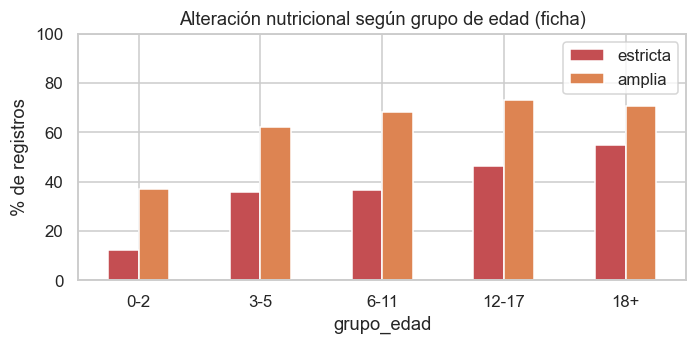

In [18]:
def estricta(txt):
    s = unicodedata.normalize("NFKD", txt.lower()).replace("tallay", "talla y").replace("riesgode", "riesgo de")
    partes = re.split(r"\s+y\s+", s)
    return int(any(("riesgo" not in p) and re.search(r"obesidad|sobrepeso|talla", p) for p in partes))
x = t.copy(); x["nutri"] = nutri_raw
x = x[~x["nutri"].str.lower().str.contains("proceso")]
x["amplia"] = (x["nutri"].str.lower() != "saludable").astype(int)
x["estricta"] = x["nutri"].map(estricta)
x["grupo_edad"] = pd.cut(x["edad_años"], [-1,2,5,11,17,40], labels=["0-2","3-5","6-11","12-17","18+"])
p = (100*x.groupby("grupo_edad")[["estricta","amplia"]].mean()).round(1); p["filas"] = x.groupby("grupo_edad").size(); print(p)
ax = p[["estricta","amplia"]].plot(kind="bar", color=["#C44E52","#DD8452"], figsize=(6.5,3.3)); ax.set_ylabel("% de registros"); ax.set_ylim(0,100)
plt.xticks(rotation=0); plt.title("Alteración nutricional según grupo de edad (ficha)"); plt.tight_layout()
plt.savefig(FIG/"step2b_alteracion_por_edad.png", bbox_inches="tight"); plt.show()

**Interpretación.** La proporción de registros con alteración **crece con la edad** en ambas etiquetas. Con la **estricta** (principal): 12,3 % en 0–2 años, 35,6 % en 3–5, 36,5 % en 6–11, 46,5 % en 12–17 y 54,9 % en mayores de edad. Con la **amplia**: de 37 % a ≈70 %. La edad es relevante y el análisis debe controlarla para no atribuir a otras variables lo que es efecto de la edad.

## 4. Reporte de selección y entendimiento de datos

**Población de análisis.** NNA acogidos en el Puericultorio Pérez Araníbar, registrados en la ficha nominal entre ene-2025 y jul-2026, con al menos una evaluación antropométrica de 2026 en un mes que también tenga ficha.

**Unidad de análisis:** una **evaluación** = un niño en un mes (medidas del Bloque 2 + etiqueta de la ficha del mismo mes).

**Criterios de inclusión:** evaluación con peso y talla, y ficha del mismo mes con diagnóstico (distinto de `En proceso de evaluación`).
**Criterios de exclusión:** NNA en provincia sin medidas; meses sin ficha (agosto); evaluaciones fuera del rango de las referencias OMS (mayores de 19 años); variables sin información.

| Hallazgo | Evidencia | Decisión (Step 3) |
|---|---|---|
| IDs reutilizados para niños distintos | 4 IDs con 2 a 5 niños | Clave de niño = ID + sexo + fecha de nacimiento |
| Fechas en 3 formatos | `AAAA-MM-DD`, `DD/MM/AAAA`, `DD/MM/AA` | Conversión formato por formato |
| Fechas imposibles | Ingreso < nacimiento (76), ingreso > registro (13), edad negativa (2) | Excluir edad negativa; ingreso inválido → imputar tiempo en el hogar |
| Etiqueta sucia | 29 variantes; `En proceso` | Descomponer en componentes → etiqueta binaria; `En proceso` = sin diagnóstico |
| Variables constantes / casi constantes | `Comunicado_DGA`, `Nacionalidad`, `Seguro`, `Capacitación` | Descartar |
| Variantes de escritura | `Si/si`, `UPE-LIMA-SUR`, soporte psicoemocional | Normalizar y agrupar |
| Fecha de nacimiento distinta entre bloques | 4 niños (2 con día/mes invertidos) | Cruce por periodo + ID; edad con la fecha del Bloque 2 |
| Bloque 2 incompleto | 6 meses, sin mayo ni julio; agosto sin ficha | Fuente de predictores; muestra pequeña (limitación) |
| Circularidad parcial | El diagnóstico clínico se basa en peso, talla y edad | La etiqueta es el registro **manual** de la ficha: se enmarca como **auditoría** de la ficha |

**Variables candidatas a predictoras (objetivo principal):** edad, sexo, peso, talla e IMC de la evaluación. Las variables administrativas de la ficha se evalúan en el Anexo (hipótesis descartada).

## Verificación y cifras de este notebook

In [19]:
assert ficha.shape == (2667, 33) and ficha["IDs_FichaNominal"].nunique() == 157
assert list(colisiones.index) == ["PPA_FN_0010", "PPA_FN_0020", "PPA_FN_0025", "PPA_FN_0127"]
assert (n_ing_ant, n_ing_post, n_edad_neg) == (76, 13, 2)
assert nutri_raw.nunique() == 29 and len(nutri) == 379
assert (par["_merge"] != "both").sum() == 11 and par.loc[par["_merge"] != "both", "IDs_FichaNominal"].nunique() == 4
assert "2026_08" not in set(ficha["periodo"])
assert p.loc["0-2", "estricta"] == 12.3 and p.loc["12-17", "estricta"] == 46.5
cifras = {"filas_ficha": len(ficha), "ids_ficha": 157, "ids_reutilizados": 4, "variantes_nivel_nutricional": 29,
          "evaluaciones_b2": len(nutri), "evaluaciones_agosto": int((nutri["periodo"] == "2026_08").sum()),
          "ninos_fecha_distinta": 4, "prev_estricta_0_2": float(p.loc["0-2", "estricta"]), "prev_estricta_12_17": float(p.loc["12-17", "estricta"])}
json.dump(cifras, open(RES/"cifras_step2b.json", "w"), indent=1); cifras

{'filas_ficha': 2667,
 'ids_ficha': 157,
 'ids_reutilizados': 4,
 'variantes_nivel_nutricional': 29,
 'evaluaciones_b2': 379,
 'evaluaciones_agosto': 32,
 'ninos_fecha_distinta': 4,
 'prev_estricta_0_2': 12.3,
 'prev_estricta_12_17': 46.5}